In [1]:
!pip install transformers
#library trained on text,audio,video , used for ex, sentiment analysis
!pip install pillow
# image processing library
!pip install torch
# ML and DL framework
!pip install torchvision
#computer vision library
!pip install torchaudio
# audio and signal processing library built specifically for the PyTorch ecosystem
!pip install gradio

In [2]:
from transformers import BlipProcessor , BlipForConditionalGeneration
from PIL import Image
import gradio as gr

W1011 17:42:01.472000 9544 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1011 17:42:01.544000 9544 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


In [3]:
processor = BlipProcessor.from_pretrained('Salesforce/blip-image-captioning-base')
model = BlipForConditionalGeneration.from_pretrained('Salesforce/blip-image-captioning-base')

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

C:\Users\yegin\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\yegin\.cache\huggingface\hub\models--Salesforce--blip-image-captioning-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

C:\Users\yegin\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\yegin\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  990MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

In [28]:
image = Image.open('assets/forest.avif')

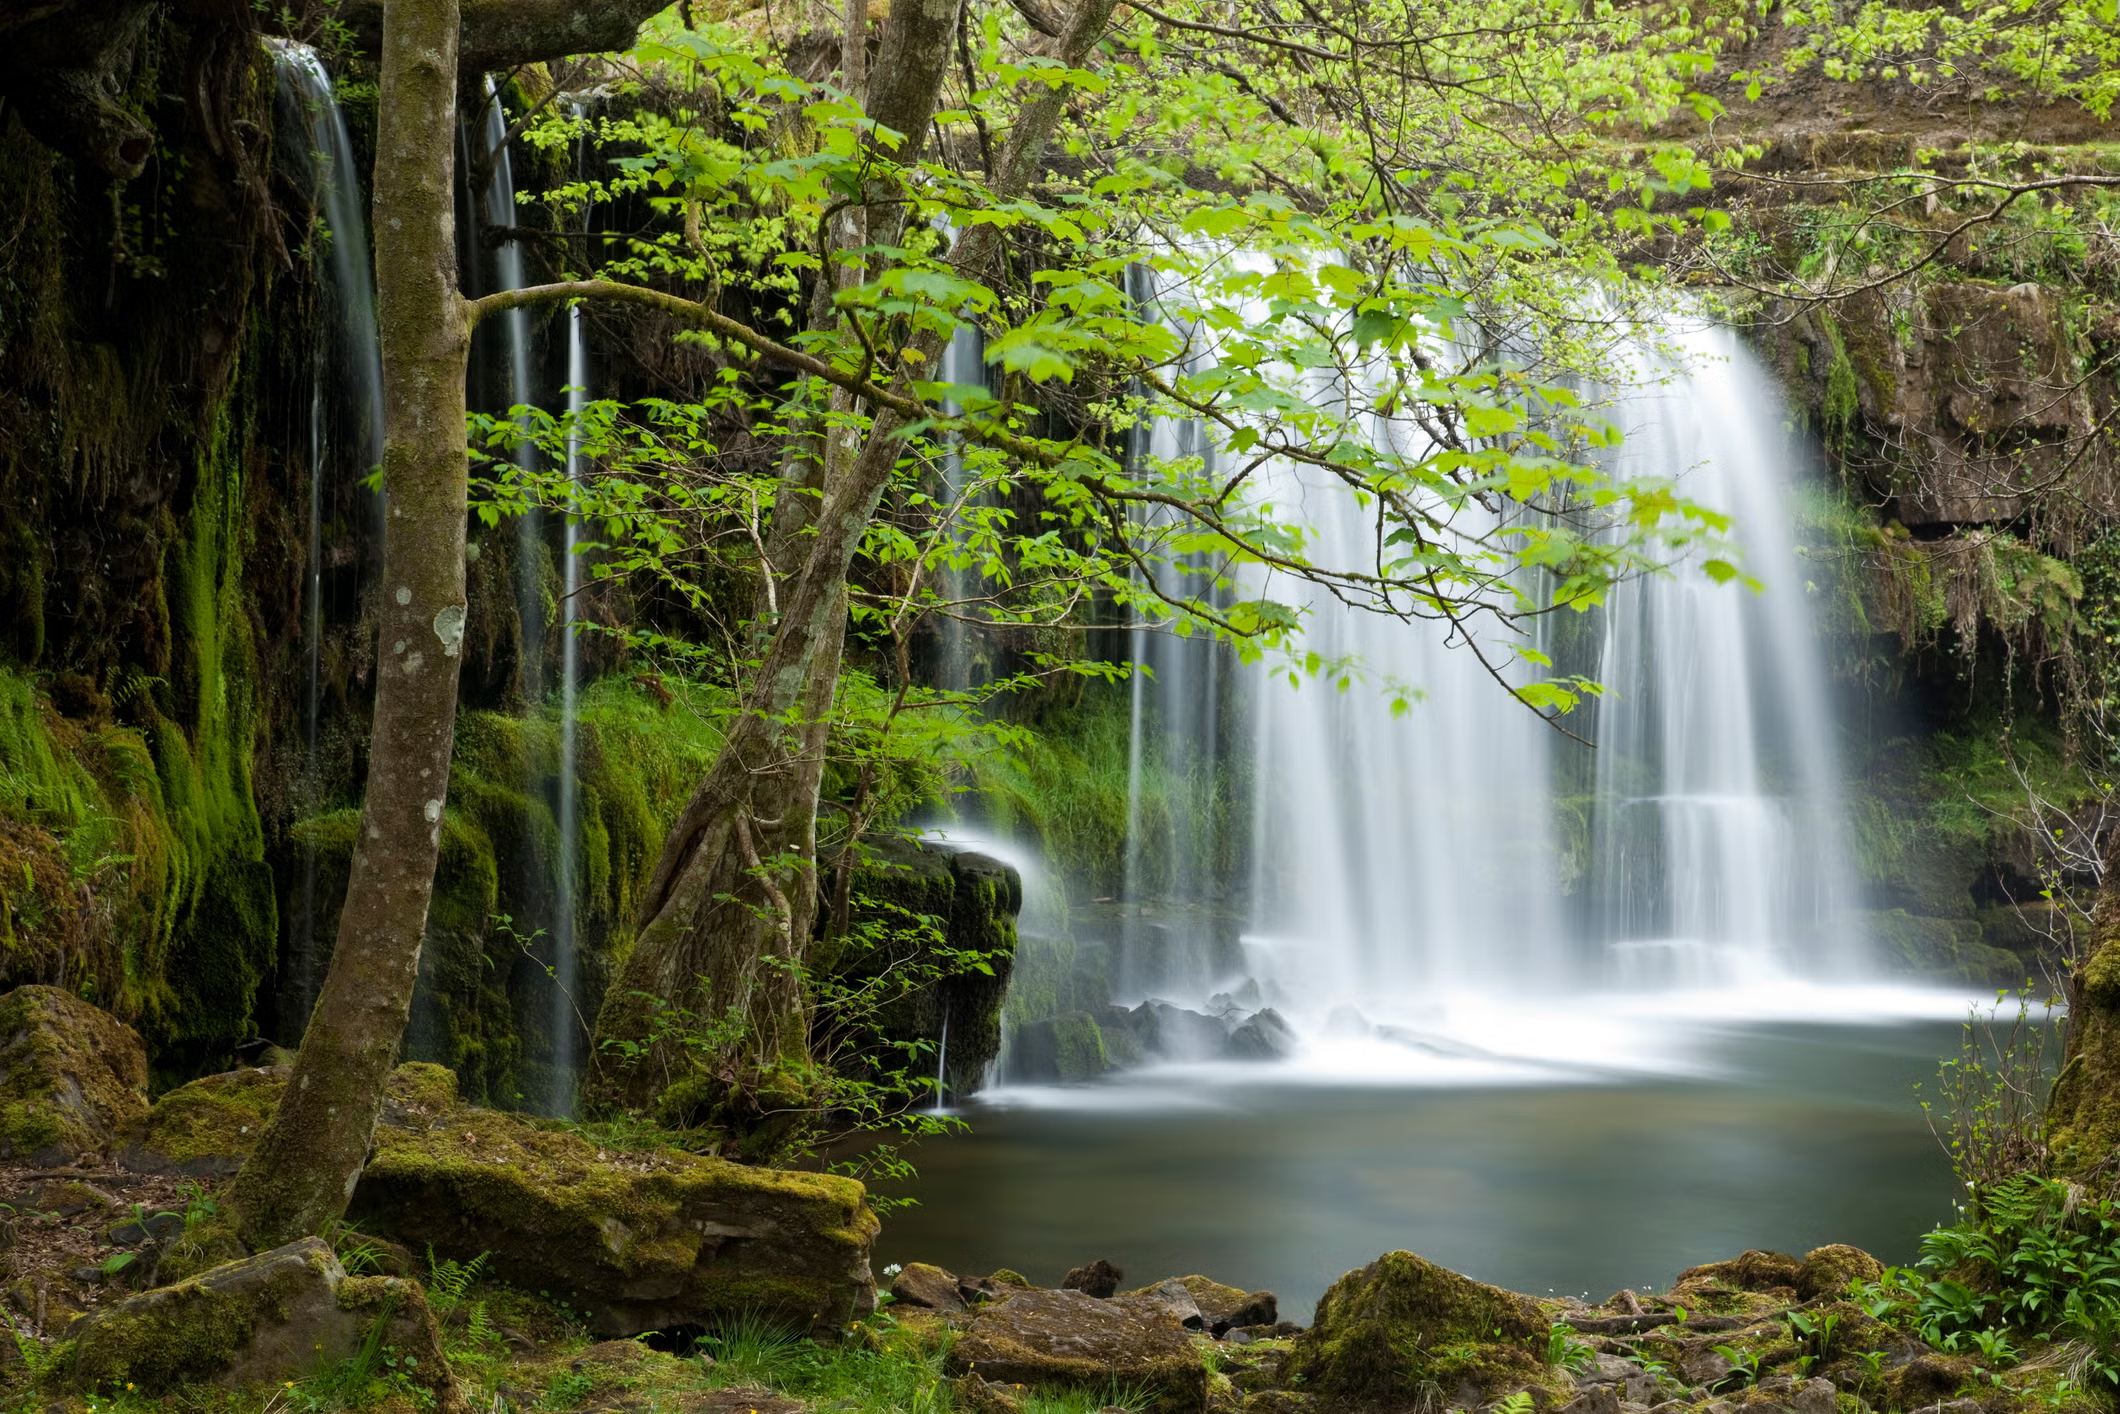

In [6]:
image

In [7]:
inputs = processor(image , return_tensors = 'pt')

In [9]:
inputs

{'pixel_values': tensor([[[[-1.6755, -1.7339, -1.7485,  ...,  0.4121,  0.2953,  0.3245],
          [-1.6609, -1.6901, -1.7485,  ...,  0.4267,  0.3099,  0.4413],
          [-1.6463, -1.6901, -1.7047,  ...,  0.4997,  0.4267,  0.5289],
          ...,
          [-0.7558, -0.8288, -0.9164,  ..., -1.0769, -0.9164, -1.3981],
          [-1.0039, -0.9602, -0.7850,  ..., -0.9602, -1.0915, -1.3689],
          [-0.8434, -0.8726, -0.7266,  ..., -1.1791, -1.1499, -1.4565]],

         [[-1.6621, -1.7071, -1.7221,  ...,  0.9193,  0.8743,  0.7992],
          [-1.6621, -1.6771, -1.7221,  ...,  1.0093,  0.9193,  0.9193],
          [-1.6470, -1.7071, -1.7221,  ...,  1.1294,  1.0844,  1.0243],
          ...,
          [-0.7316, -0.8216, -0.9267,  ..., -0.9567, -0.7616, -1.3469],
          [-1.1368, -0.8816, -0.5815,  ..., -0.8967, -1.0017, -1.3469],
          [-0.6865, -0.6715, -0.4914,  ..., -1.1668, -1.1068, -1.4519]],

         [[-1.4518, -1.4802, -1.4660,  ..., -0.9541, -1.2811, -0.4990],
          [-1

In [10]:
outputs = model.generate(**inputs)

/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1954: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


In [11]:
outputs

tensor([[30522,  1037, 14297,  1999,  1996,  3224,   102]])

In [17]:
caption = processor.decode(outputs[0] , skip_special_tokens = True)

In [18]:
caption

'a waterfall in the forest'

In [19]:
from glob import glob

In [25]:
g = glob('/content/assets/*')

In [26]:
g

['/content/assets/geometry.jfif',
 '/content/assets/green.avif',
 '/content/assets/forest.avif',
 '/content/assets/math.avif',
 '/content/assets/animals.webp']

In [4]:
def img_caption(image):
  # path = img_path.split('/', 2)[-1]
  # image = Image.open(path)
  inputs = processor(image , return_tensors = 'pt')
  outputs = model.generate(**inputs)
  return processor.decode(outputs[0] , skip_special_token = True)


In [43]:
caption = []
for path in g :
  caption.append(img_caption(path))

<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=420x420 at 0x788553CF1E00>


/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1954: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


<PIL.AvifImagePlugin.AvifImageFile image mode=RGB size=600x400 at 0x788553C09A30>
<PIL.AvifImagePlugin.AvifImageFile image mode=RGB size=2120x1414 at 0x788553CECE20>
<PIL.AvifImagePlugin.AvifImageFile image mode=RGB size=626x626 at 0x788553CECE20>
<PIL.WebPImagePlugin.WebPImageFile image mode=RGB size=480x320 at 0x788553CE51D0>


In [44]:
caption

['seamless vector pattern with hand drawn formulas and formulas on a green background illustration [SEP]',
 'the river in the forest with mountains in the background [SEP]',
 'a waterfall in the forest [SEP]',
 'math doo doo doo doo doo doo doo doo doo doo doo doo doo doo doo doo doo doo doo',
 'a group of animals and birds in a field [SEP]']

In [10]:
ui = gr.Interface(
    fn = img_caption,
    inputs = gr.Image(type='pil'),
    outputs = 'text',
    title = "Image captioning",
    description = "Select your image and get caption"
)

In [11]:
ui.launch()

* Running on local URL:  http://127.0.0.1:7864
* To create a public link, set `share=True` in `launch()`.
